# Trancón fantasma en una vía circular

**Física A: Hardware e Información** · Universidad de los Andes · 2026-2
**Integrantes:** Iker Barbosa (202424135) y [nombre y código del compañero] · **Profesor:** Julián Rincón

**Cómo leer este notebook.** Cada bloque de código va precedido de una celda que dice *qué hace y por qué* y seguido de una celda de *interpretación*. Las ecuaciones se construyen desde cinemática y leyes de Newton; cada parámetro tiene una fuente en la sección 2.6. Ejecutar todo de principio a fin toma ≈ 1 minuto.

**Librerías necesarias:** `numpy`, `matplotlib` y la librería estándar de Python (`math`). Para mostrar la animación dentro del notebook se usa además `IPython.display`, que viene con Jupyter; si no está disponible, la animación se guarda igual como `anillo.gif`.

In [1]:
import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

print("NumPy " + np.__version__)
print("Matplotlib " + matplotlib.__version__)

# Estilo de las gráficas: un solo color para los datos, gris para las referencias
COLOR_DATO = "#2a5d9f"
COLOR_REF = "#7a7a7a"
TINTA = "#222222"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": COLOR_REF, "axes.labelcolor": TINTA,
                     "xtick.color": TINTA, "ytick.color": TINTA,
                     "axes.grid": True, "grid.color": "#e3e3e3", "grid.linewidth": 0.6,
                     "figure.dpi": 100})

NumPy 2.5.3
Matplotlib 3.11.2


## 1. Pregunta

> **¿A partir de qué densidad de carros la reducción de velocidad de un solo carro se amplifica hasta formar un trancón (una onda de frenado que viaja hacia atrás) en una vía circular, sin accidente ni obstáculo?**

### 1.1 Por qué importa
Hay trancones que aparecen sin causa externa visible: no hay accidente, semáforo ni obstáculo. La idea es que nacen de la *interacción* entre conductores: cada uno reacciona solo al carro de adelante, y una pequeña reducción de velocidad se puede amplificar al propagarse hacia atrás. Una vía circular permite estudiarlo de forma aislada: no hay entradas ni salidas y el número de carros se conserva.

Esto se ha observado en experimentos reales. Sugiyama et al. (2008) pusieron 22 carros a dar vueltas en una pista circular de 230 m, y sin ningún obstáculo apareció un trancón que viajaba hacia atrás. Tadaki et al. (2013) repitieron el experimento en una pista de 314 m variando entre 10 y 40 carros y encontraron que el trancón aparece cuando la densidad pasa de un valor crítico, entre 0,08 y 0,09 carros/m. Usaremos esos experimentos para validar el modelo (sección 5.3).

### 1.2 Hipótesis (a contrastar, no a asumir)
1. Por debajo de una densidad crítica $\rho_c$ la perturbación se disipa.
2. Por encima de $\rho_c$ la perturbación crece solo si además $\tau > T/2$ (criterio publicado, ver 2.5).
3. Con $N$ finito, el umbral real de $\tau$ queda algo por encima de $T/2$ (se verifica en 4.3 y 5.1).

## 2. Modelo físico

### 2.1 Sistema, variables y suposiciones
$N$ carros de largo $\ell$ en un anillo de longitud $L$. La densidad es $\rho = N/L$.

| Símbolo | Significado | Unidad |
|---|---|---|
| $N$ | número de carros | – |
| $L$ | longitud del anillo | m |
| $\ell$ | largo de cada carro | m |
| $x_i$ | posición del carro $i$ a lo largo del anillo | m |
| $v_i$, $a_i$ | velocidad y aceleración del carro $i$ | m/s, m/s² |
| $s_i$ | distancia libre al carro de adelante | m |
| $T$ | tiempo de separación deseado | s |
| $s_0$ | distancia mínima de seguridad | m |
| $v_{max}$ | velocidad máxima | m/s |
| $\tau$ | tiempo de respuesta del conductor | s |
| $\delta$ | reducción inicial de velocidad del carro 1 | m/s |

**Suposiciones.**
1. Una sola fila, un carril, sin adelantamientos: el orden de los carros se conserva.
2. Cada conductor reacciona solo al carro de adelante.
3. Todos los carros y conductores son iguales (mismos $\ell$, $T$, $s_0$, $v_{max}$, $\tau$).
4. Sin ruido, semáforos ni obstáculos: la única perturbación es la inicial.
5. Los carros se numeran $1,\dots,N$ en el sentido de la marcha; el carro $N$ sigue al carro $1$ una vuelta adelante.

### 2.2 Cinemática
$$\frac{dx_i}{dt} = v_i, \qquad a_i = \frac{dv_i}{dt}$$

La distancia libre al carro de adelante es
$$s_i = x_{i+1} - x_i - \ell \quad (i<N), \qquad s_N = x_1 + L - x_N - \ell$$

### 2.3 Velocidad deseada $V(s)$ (desde movimiento uniforme)
Un conductor que va a velocidad $v$ quiere quedar a $T$ segundos del carro de adelante y, además, a una distancia mínima $s_0$. En $T$ segundos recorre $vT$ (movimiento uniforme), así que necesita
$$s \ge s_0 + vT \;\Longrightarrow\; v \le \frac{s-s_0}{T}$$
Con un tope $v_{max}$, la velocidad deseada es
$$V(s)=\begin{cases}0 & s\le s_0\\[2pt] \dfrac{s-s_0}{T} & s_0<s<s_0+v_{max}T\\[6pt] v_{max} & s\ge s_0+v_{max}T\end{cases}$$

### 2.4 Segunda ley de Newton
Se modela la fuerza neta sobre el carro $i$ como una fuerza que lo empuja hacia su velocidad deseada:
$$m\,a_i = F_i = \frac{m}{\tau}\bigl(V(s_i)-v_i\bigr) \;\Longrightarrow\; \boxed{a_i=\frac{V(s_i)-v_i}{\tau}}$$
Tiene la misma estructura que la caída con arrastre lineal, $m\,dv/dt=-b(v-v_T)$ con $\tau=m/b$, pero aquí la "velocidad terminal" $V(s_i)$ **depende de la distancia al carro de adelante**.

- Si $v_i<V(s_i)$ el carro acelera, si $v_i>V(s_i)$ frena y si $v_i=V(s_i)$ no cambia.
- $\tau$ **no es el tiempo de separación** (ese es $T$): es lo que tarda el conductor en ajustar su velocidad a la deseada.
- Esta fuerza es una **suposición del modelo** sobre el conductor, no una ley de la naturaleza.
- Este modelo coincide con el *modelo de velocidad óptima* de Bando et al. (1995), con una velocidad deseada lineal por tramos. Por eso hay resultados publicados con los que comparar.

### 2.5 Equilibrio y predicciones analíticas
**Flujo uniforme.** Si todos van a la misma velocidad y con el mismo espacio libre, $s_e = L/N-\ell$ y $v_e=V(s_e)$. Entonces $a_i=0$ para todos, las distancias libres no cambian y es una solución exacta.

**Densidad crítica.** Si $s_e \ge s_0+v_{max}T$, todos van a $v_{max}$ y $V$ es constante: $a_i=(v_{max}-v_i)/\tau$, de modo que cualquier desviación de velocidad decae exponencialmente (como en la caída con arrastre). El límite es
$$s_e = s_0+v_{max}T \;\Longrightarrow\; \rho_c=\frac{1}{\ell+s_0+v_{max}T}, \qquad N_c=\frac{L}{\ell+s_0+v_{max}T}$$

**Criterio para $\tau$.** Por encima de $\rho_c$ estamos en el tramo inclinado de $V$, que es exactamente lineal con $V'=1/T$. Linealizando alrededor del flujo uniforme ($v_i=v_e+u_i$, $s_i=s_e+\sigma_i$):
$$\dot\sigma_i = u_{i+1}-u_i, \qquad \dot u_i = \frac{V'\sigma_i-u_i}{\tau}$$
El análisis de modos de estas ecuaciones da el criterio publicado $V' > a/2$ con $a=1/\tau$ (Bando et al. 1995; Nakayama et al. 2016, ec. 2), es decir
$$\boxed{\tau>\frac{T}{2}}$$
**No derivamos el análisis de modos:** usamos el criterio como predicción citada y lo verificamos con la simulación (secciones 4.3 y 5.1). Es válido para perturbaciones de longitud de onda larga; con $N$ finito el umbral real puede quedar algo por encima.

### 2.6 Parámetros y sus fuentes
Todos salen de experimentos publicados en pistas circulares, salvo $\delta$ y $\Delta t$, que son decisión nuestra. El único que ajustamos es $\tau$, y por eso se reporta como barrido.

| Parámetro | Valor | Fuente |
|---|---|---|
| Longitud de la pista $L$ | 314 m | Tadaki et al. 2013 |
| Largo del carro $\ell$ | 3,885 m | Tadaki et al. 2013 (Toyota Vitz) |
| Distancia mínima $s_0$ | 2 m | Nakayama et al. 2016 (separación mínima ≈ 6 m = largo + 2 m) |
| Velocidad máxima $v_{max}$ | 11,1 m/s (40 km/h) | Tadaki et al. 2013 (flujo libre ≈ 40 km/h) |
| Tiempo de separación $T$ | 1 s | Nakayama et al. 2016, ec. 4 (6 m / 6 m/s) |
| Tiempo de respuesta $\tau$ | 0,5 / 0,7 / 1,0 s y otros | Barrido. El valor publicado (≈ 0,56 s) queda casi en el umbral $T/2$ |
| Perturbación inicial $\delta$ | 0,5 m/s | Decisión nuestra |
| Paso de tiempo $\Delta t$ | 0,02 s | Decisión nuestra, verificada con $2\Delta t$ (5.2) |
| Número de carros $N$ | 10 a 40 | Rango de Tadaki et al. 2013 |

El valor de trabajo es $\tau=0{,}7$ s: con $\tau=0{,}5$ s el flujo es estable, con $0{,}7$ s se forma el trancón sin choques y desde $0{,}8$ s aparecen distancias negativas (se muestra en 4.3).

**Qué hace y por qué.** Define los parámetros en un solo lugar y calcula los valores que predice la teoría ($\rho_c$, $N_c$, $T/2$) para compararlos después con la simulación.

In [2]:
# Parámetros (fuente de cada uno en la tabla de la sección 2.6)
L = 314.0            # longitud de la pista (m)
ell = 3.885          # largo del carro (m)
s0 = 2.0             # distancia mínima (m)
vmax = 40 / 3.6      # velocidad máxima: 40 km/h pasados a m/s
T = 1.0              # tiempo de separación deseado (s)
tau = 0.7            # tiempo de respuesta (s), valor de trabajo; se barre en 4.3
delta = 0.5          # reducción inicial de velocidad del carro 1 (m/s)
dt = 0.02            # paso de tiempo (s)

# Predicciones analíticas (sección 2.5)
rho_c = 1.0 / (ell + s0 + vmax * T)
N_c = L * rho_c

print("Velocidad máxima v_max = " + str(round(vmax, 2)) + " m/s")
print("Densidad crítica rho_c = " + str(round(rho_c, 4)) + " carros/m")
print("N crítico N_c = " + str(round(N_c, 2)) + " carros")
print("Umbral de tau según el criterio publicado: T/2 = " + str(T / 2) + " s")

Velocidad máxima v_max = 11.11 m/s
Densidad crítica rho_c = 0.0588 carros/m
N crítico N_c = 18.47 carros
Umbral de tau según el criterio publicado: T/2 = 0.5 s


**Interpretación.** $N_c\approx 18{,}5$ no es entero, así que el cambio de régimen debe verse entre $N=18$ y $N=19$: con 18 carros la teoría dice que todo decae, con 19 que la perturbación puede crecer. Eso es lo que se comprueba en 4.2 y 5.1.

## 3. Método numérico

### 3.1 Por qué hace falta simular
El modelo son $2N$ ecuaciones diferenciales acopladas ($x_i$ y $v_i$), con una $V(s)$ definida por tramos. No hay solución analítica general fuera del flujo uniforme, así que se integra en el tiempo con pasos $\Delta t$.

### 3.2 Euler explícito
Se aproxima la derivada por su definición con un paso finito, $\dot v \approx (v^{n+1}-v^n)/\Delta t$, lo que da
$$a_i^n=\frac{V(s_i^n)-v_i^n}{\tau},\qquad v_i^{n+1}=v_i^n+a_i^n\,\Delta t,\qquad x_i^{n+1}=x_i^n+v_i^{n+1}\,\Delta t$$
Es cinemática por pasos: la aceleración se supone constante durante cada paso. Para mover el carro usamos la velocidad ya actualizada, $v^{n+1}$. Con la velocidad vieja, $v^n$, para $N=30$ y $\tau=0{,}7$ s la distancia libre mínima baja de 0,50 m a 0,32 m y la velocidad media cambia 0,6 %, por lo que la conclusión no depende de esa elección.

### 3.3 Condición inicial
$$x_i(0)=\frac{(i-1)L}{N},\qquad v_i(0)=v_e\;(i\ne1),\qquad v_1(0)=v_e-\delta$$
Es el flujo uniforme con **una sola** perturbación: el carro 1 arranca $\delta$ más lento.

### 3.4 Implementación
Se definen funciones con una sola tarea cada una; el docstring dice qué ecuación de la sección 2 implementa.

**Qué hace y por qué.** `V_deseada` (2.3), `distancias_libres` (2.2), `aceleracion` (2.4), `paso_euler` (3.2), `condicion_inicial` (3.3) y `simular`, que repite el paso hasta el tiempo final y guarda los resultados cada 0,5 s.

*Cuidado con el anillo:* las distancias libres se calculan sumando $L$ **solo** al último carro. Usar `% L` ocultaría las colisiones, porque una distancia negativa se convertiría en una positiva casi igual a $L$.

In [3]:
def V_deseada(s):
    """Velocidad deseada V(s) de la ecuación 2.3 (s en m, devuelve m/s)."""
    return np.clip((s - s0) / T, 0.0, vmax)


def distancias_libres(x, L):
    """Distancia libre s_i al carro de adelante (ecuación 2.2). Solo el último carro suma L."""
    s = np.empty_like(x)
    s[:-1] = x[1:] - x[:-1] - ell
    s[-1] = x[0] + L - x[-1] - ell
    return s


def aceleracion(x, v, L, tau):
    """Segunda ley de Newton del modelo, a_i = (V(s_i) - v_i) / tau (ecuación 2.4)."""
    return (V_deseada(distancias_libres(x, L)) - v) / tau


def paso_euler(x, v, dt, L, tau):
    """Un paso de Euler (ecuación 3.2): primero la velocidad, luego la posición con la velocidad nueva."""
    a = aceleracion(x, v, L, tau)
    v_nueva = v + a * dt
    x_nueva = x + v_nueva * dt
    return x_nueva, v_nueva


def condicion_inicial(N, L, delta):
    """Flujo uniforme con el carro 1 más lento en delta (ecuación 3.3)."""
    x = np.arange(N) * L / N
    s_e = L / N - ell
    v = np.full(N, V_deseada(s_e))
    v[0] = v[0] - delta
    return x, v


def simular(N, tau, L=L, delta=delta, dt=dt, tf=1500.0, dt_reg=0.5):
    """Simula N carros hasta tf. Devuelve tiempos, posiciones, velocidades
    (guardadas cada dt_reg segundos) y la distancia libre mínima de toda la corrida."""
    x, v = condicion_inicial(N, L, delta)
    n_pasos = int(round(tf / dt))
    cada = int(round(dt_reg / dt))
    t_reg = [0.0]
    x_reg = [x.copy()]
    v_reg = [v.copy()]
    s_min = distancias_libres(x, L).min()
    for k in range(1, n_pasos + 1):
        x, v = paso_euler(x, v, dt, L, tau)
        s_min = min(s_min, distancias_libres(x, L).min())
        if k % cada == 0:
            t_reg.append(k * dt)
            x_reg.append(x.copy())
            v_reg.append(v.copy())
    return np.array(t_reg), np.array(x_reg), np.array(v_reg), s_min


def amplitud(V):
    """A(t) = v máxima - v mínima entre todos los carros, para cada instante."""
    return V.max(axis=1) - V.min(axis=1)


def amplitud_final(t, V, ventana=10.0):
    """Promedio de A(t) en los últimos 'ventana' segundos (definido por tiempo, no por pasos)."""
    return amplitud(V)[t >= t[-1] - ventana].mean()


def valor_inc(valor, inc):
    """Texto '(valor ± incertidumbre)' con 1 cifra significativa en la incertidumbre."""
    if inc <= 0:
        return str(valor)
    inc = float("%.1g" % inc)                      # 1 cifra significativa (0.96 pasa a 1.0)
    decimales = -int(math.floor(math.log10(inc)))
    if decimales <= 0:
        return "(" + str(int(round(valor, decimales))) + " ± " + str(int(round(inc, decimales))) + ")"
    return "(" + str(round(valor, decimales)) + " ± " + str(round(inc, decimales)) + ")"

**Interpretación / prueba de cordura.** Con $\delta=0$ el flujo uniforme debe quedarse uniforme: es solución exacta. Si la amplitud no es ≈ 0 hasta error de máquina, hay un error de código y no tiene sentido mirar ningún resultado.

In [4]:
t0, X0, V0, s_min0 = simular(30, tau, delta=0.0, tf=300.0)
print("Con delta = 0, N = 30: amplitud máxima = " + str(amplitud(V0).max()) + " m/s")
print("Distancia libre mínima = " + str(round(s_min0, 3)) + " m")

Con delta = 0, N = 30: amplitud máxima = 1.2320811038080137e-11 m/s
Distancia libre mínima = 6.582 m


**Interpretación.** La amplitud es del orden de $10^{-11}$ m/s, es decir, error de redondeo: el código mantiene el flujo uniforme tal como predice la teoría. Todo lo que aparezca de aquí en adelante viene de la perturbación $\delta$, no de un error del programa.

## 4. Resultados

**Métrica de amplitud.** $A(t)=\max_i v_i(t)-\min_i v_i(t)$. La *amplitud final* es el promedio de $A$ en los **últimos 10 s** de la simulación. Si $A\approx0$, todos los carros van igual y no hay trancón. Si $A\approx v_{max}$, hay carros detenidos y carros a velocidad máxima al mismo tiempo.

### 4.1 Un caso representativo ($N=30$, $\tau=0{,}7$ s)
**Qué hace y por qué.** Muestra el fenómeno completo en un caso. Tres vistas de la misma simulación: el anillo al inicio y con el trancón formado (cada carro coloreado por su velocidad, más oscuro = más lento), el diagrama espacio-tiempo (si hay onda de frenado se ven franjas oscuras que se mueven hacia atrás) y la amplitud $A(t)$ (si crece, la perturbación se amplifica).

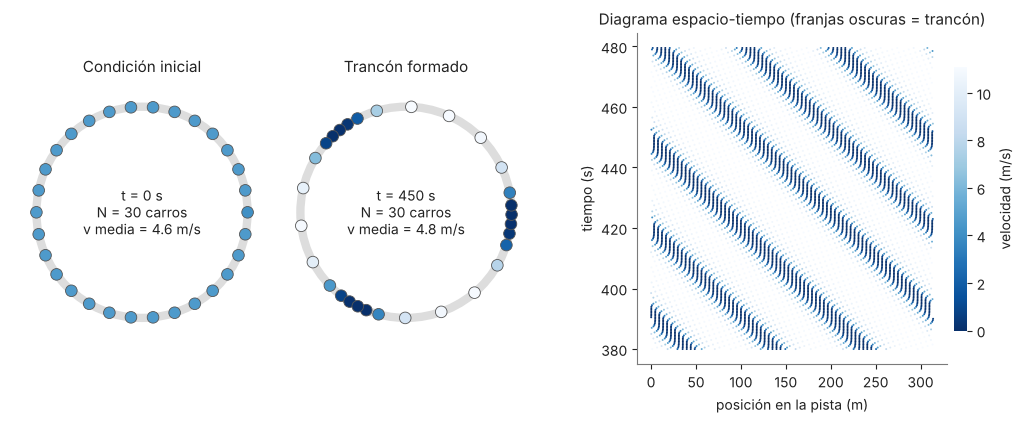

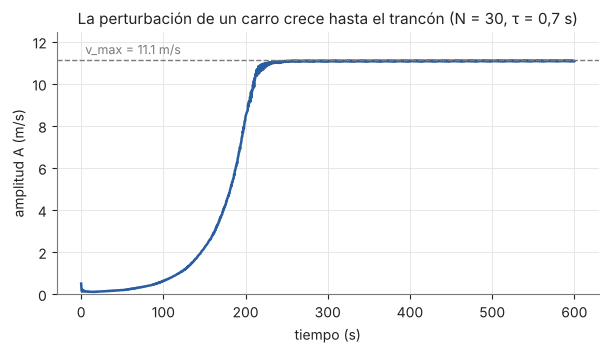

A supera 1 m/s en t = 119.5 s y supera 5 m/s en t = 181.5 s
Distancia libre mínima de la corrida = 0.51 m


In [5]:
N_rep = 30
t, X, V, s_min = simular(N_rep, tau, tf=600.0)
R = L / (2 * np.pi)                                # radio del círculo para dibujar el anillo
mapa = plt.get_cmap("Blues_r")                     # una sola tonalidad: oscuro = lento
norma = matplotlib.colors.Normalize(0, vmax)


def dibujar_anillo(ax, k):
    """Dibuja los carros en el instante t[k] sobre un círculo, coloreados por su velocidad."""
    ang = (X[k] % L) * 2 * np.pi / L
    ax.clear()
    ax.add_patch(plt.Circle((0, 0), R, fill=False, ec="#dddddd", lw=6))
    puntos = ax.scatter(R * np.cos(ang), R * np.sin(ang), c=V[k], cmap=mapa, norm=norma,
                        s=70, edgecolors="#555555", linewidths=0.6, zorder=3)
    ax.set_xlim(-1.25 * R, 1.25 * R)
    ax.set_ylim(-1.25 * R, 1.25 * R)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.text(0, 0, "t = " + str(int(t[k])) + " s\nN = " + str(N_rep) + " carros\nv media = "
            + str(round(V[k].mean(), 1)) + " m/s", ha="center", va="center", color=TINTA, fontsize=10)
    return puntos


fig = plt.figure(figsize=(11, 4.6))
ax1 = fig.add_axes([0.01, 0.08, 0.24, 0.8])
ax2 = fig.add_axes([0.25, 0.08, 0.24, 0.8])
ax3 = fig.add_axes([0.58, 0.15, 0.30, 0.72])
dibujar_anillo(ax1, 0)
puntos = dibujar_anillo(ax2, int(450 / 0.5))
ax1.set_title("Condición inicial", color=TINTA, fontsize=11)
ax2.set_title("Trancón formado", color=TINTA, fontsize=11)

k0, k1 = int(380 / 0.5), int(480 / 0.5)             # ventana de 100 s para el diagrama espacio-tiempo
for i in range(N_rep):
    ax3.scatter(X[k0:k1, i] % L, t[k0:k1], c=V[k0:k1, i], cmap=mapa, norm=norma, s=2, linewidths=0)
ax3.set_xlabel("posición en la pista (m)")
ax3.set_ylabel("tiempo (s)")
ax3.set_title("Diagrama espacio-tiempo (franjas oscuras = trancón)", fontsize=11, color=TINTA)
ax3.grid(False)
barra = fig.colorbar(puntos, ax=ax3, fraction=0.04, pad=0.02)
barra.set_label("velocidad (m/s)")
barra.outline.set_visible(False)
plt.show()

A = amplitud(V)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(t, A, color=COLOR_DATO, lw=1.8)
ax.axhline(vmax, color=COLOR_REF, lw=1, ls="--")
ax.text(5, vmax + 0.3, "v_max = " + str(round(vmax, 1)) + " m/s", color=COLOR_REF, fontsize=9)
ax.set_xlabel("tiempo (s)")
ax.set_ylabel("amplitud A (m/s)")
ax.set_title("La perturbación de un carro crece hasta el trancón (N = 30, τ = 0,7 s)", fontsize=11, color=TINTA)
ax.set_ylim(0, vmax * 1.12)
plt.show()

print("A supera 1 m/s en t = " + str(t[np.argmax(A > 1)]) + " s y supera 5 m/s en t = " + str(t[np.argmax(A > 5)]) + " s")
print("Distancia libre mínima de la corrida = " + str(round(s_min, 2)) + " m")

**Interpretación.** Los carros parten espaciados de forma uniforme y, sin ningún obstáculo, aparecen franjas oscuras (carros casi detenidos) que **se mueven hacia atrás** respecto al sentido de la marcha: en el diagrama espacio-tiempo suben hacia la izquierda, mientras los carros avanzan hacia la derecha. La amplitud empieza en $\delta=0{,}5$ m/s, baja a ≈ 0,1 m/s en los primeros 16 s (la perturbación primero se atenúa) y después crece cada vez más rápido: supera 1 m/s hacia los 120 s, 5 m/s hacia los 180 s y se **satura en $v_{max}$** (11,1 m/s), es decir, ya hay carros detenidos y carros a velocidad máxima. La distancia libre mínima (≈ 0,5 m) es positiva: no hay choques.

Con $N=30$ aparecen **tres trancones a la vez** (se cuenta en 5.3), no uno. Es una diferencia con los experimentos que se discute en 5.3 y 6.

**Animación.** La misma simulación vista como carros que dan vueltas (60 s, de $t=350$ a $t=410$ s). Se guarda en `anillo.gif` y, si `IPython.display` está disponible, se muestra aquí.

Animación guardada en anillo.gif (120 cuadros)


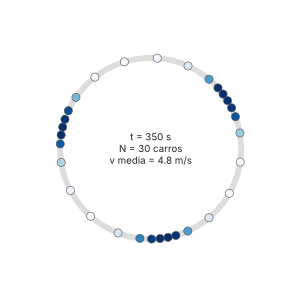

In [6]:
fig_a, ax_a = plt.subplots(figsize=(4.2, 4.2), dpi=70)
cuadros = range(int(350 / 0.5), int(410 / 0.5))


def actualizar(k):
    dibujar_anillo(ax_a, k)
    return []


animacion = FuncAnimation(fig_a, actualizar, frames=cuadros, blit=False)
animacion.save("anillo.gif", writer=PillowWriter(fps=15))
plt.close(fig_a)
print("Animación guardada en anillo.gif (" + str(len(cuadros)) + " cuadros)")

try:
    from IPython.display import Image, display
    display(Image(filename="anillo.gif"))
except ImportError:
    print("IPython.display no está disponible: abrir anillo.gif aparte.")

**Interpretación.** En la animación se ve cómo cada carro llega al final de un grupo detenido, espera y vuelve a acelerar cuando el de adelante arranca, mientras el grupo como tal se desplaza hacia atrás. Ningún carro está programado para "hacer un trancón": es un comportamiento colectivo que sale de la regla local $a_i=(V(s_i)-v_i)/\tau$.

### 4.2 Barrido en el número de carros $N$ (densidad)
**Qué hace y por qué.** Responde la pregunta central: se repite la simulación variando $N$ de 10 a 40 (con $\tau=0{,}7$ s) y se grafica la amplitud final contra la densidad $\rho=N/L$, marcando $\rho_c$. Son 31 simulaciones de 1500 s y tarda ≈ 30 s.

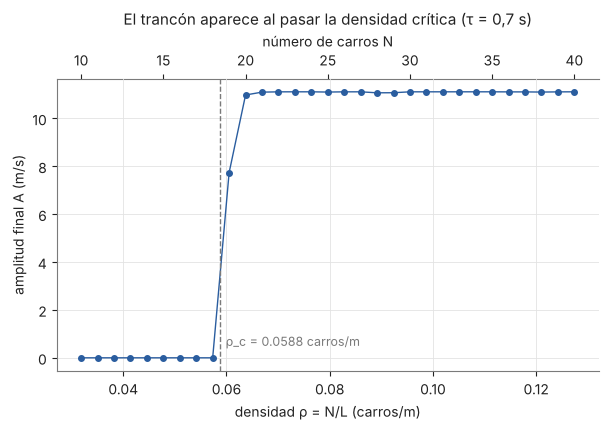

N = 17: amplitud final = 0.0 m/s
N = 18: amplitud final = 0.0 m/s
N = 19: amplitud final = 7.74 m/s
N = 20: amplitud final = 10.98 m/s
N = 22: amplitud final = 11.11 m/s


In [7]:
Ns = np.arange(10, 41)
A_fin_N = np.zeros(len(Ns))
s_min_N = np.zeros(len(Ns))
for j in range(len(Ns)):
    t_j, X_j, V_j, s_min_j = simular(int(Ns[j]), tau, tf=1500.0)
    A_fin_N[j] = amplitud_final(t_j, V_j)
    s_min_N[j] = s_min_j

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(Ns / L, A_fin_N, "o-", color=COLOR_DATO, ms=4, lw=1)
ax.axvline(rho_c, color=COLOR_REF, ls="--", lw=1)
ax.text(rho_c + 0.001, 0.5, "ρ_c = " + str(round(rho_c, 4)) + " carros/m", color=COLOR_REF, fontsize=9)
ax.set_xlabel("densidad ρ = N/L (carros/m)")
ax.set_ylabel("amplitud final A (m/s)")
ax.set_title("El trancón aparece al pasar la densidad crítica (τ = 0,7 s)", fontsize=11, color=TINTA)
arriba = ax.secondary_xaxis("top", functions=(lambda r: r * L, lambda n: n / L))
arriba.set_xlabel("número de carros N")
plt.show()

for j in range(len(Ns)):
    if Ns[j] in (17, 18, 19, 20, 22):
        print("N = " + str(Ns[j]) + ": amplitud final = " + str(round(A_fin_N[j], 2)) + " m/s")

**Interpretación.** La amplitud final es **cero** hasta $N=18$ (la perturbación se disipa), pasa a 7,7 m/s con $N=19$ y llega a $v_{max}$ (11,1 m/s) desde $N\approx22$. El salto ocurre entre $N=18$ y $N=19$, que es exactamente donde la teoría pone $N_c\approx18{,}5$. Con $N=19$ la amplitud aún no ha saturado a los 1500 s porque, justo por encima de $\rho_c$, el crecimiento es lento. Esto responde la pregunta en el modelo: **la perturbación de un carro se amplifica cuando la densidad supera $\rho_c\approx0{,}059$ carros/m** (siempre que $\tau>T/2$, ver 4.3).

### 4.3 Barrido en $\tau$ (con $N=30$)
**Qué hace y por qué.** Dentro del tramo inclinado, el criterio $\tau>T/2$ no depende de la densidad. Se barre $\tau$ y se grafican (izquierda) la amplitud final, marcando $T/2$, y (derecha) la distancia libre mínima, porque una distancia negativa significa que dos carros se atravesaron y el resultado deja de ser físicamente creíble.

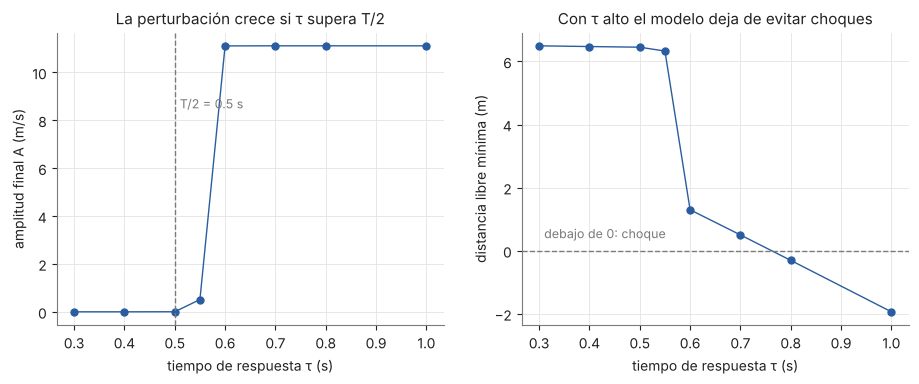

tau = 0.3 s: amplitud final = 0.0 m/s, distancia libre mínima = 6.49 m
tau = 0.4 s: amplitud final = 0.0 m/s, distancia libre mínima = 6.47 m
tau = 0.5 s: amplitud final = 0.002 m/s, distancia libre mínima = 6.45 m
tau = 0.55 s: amplitud final = 0.512 m/s, distancia libre mínima = 6.33 m
tau = 0.6 s: amplitud final = 11.107 m/s, distancia libre mínima = 1.3 m
tau = 0.7 s: amplitud final = 11.111 m/s, distancia libre mínima = 0.5 m
tau = 0.8 s: amplitud final = 11.111 m/s, distancia libre mínima = -0.3 m
tau = 1.0 s: amplitud final = 11.111 m/s, distancia libre mínima = -1.94 m


In [8]:
taus = np.array([0.3, 0.4, 0.5, 0.55, 0.6, 0.7, 0.8, 1.0])
A_fin_tau = np.zeros(len(taus))
s_min_tau = np.zeros(len(taus))
for j in range(len(taus)):
    t_j, X_j, V_j, s_min_j = simular(30, taus[j], tf=1500.0)
    A_fin_tau[j] = amplitud_final(t_j, V_j)
    s_min_tau[j] = s_min_j

fig, (axa, axb) = plt.subplots(1, 2, figsize=(11, 3.8))
axa.plot(taus, A_fin_tau, "o-", color=COLOR_DATO, ms=5, lw=1)
axa.axvline(T / 2, color=COLOR_REF, ls="--", lw=1)
axa.text(T / 2 + 0.01, 8.5, "T/2 = " + str(T / 2) + " s", color=COLOR_REF, fontsize=9)
axa.set_xlabel("tiempo de respuesta τ (s)")
axa.set_ylabel("amplitud final A (m/s)")
axa.set_title("La perturbación crece si τ supera T/2", fontsize=11, color=TINTA)

axb.plot(taus, s_min_tau, "o-", color=COLOR_DATO, ms=5, lw=1)
axb.axhline(0, color=COLOR_REF, ls="--", lw=1)
axb.text(0.31, 0.4, "debajo de 0: choque", color=COLOR_REF, fontsize=9)
axb.set_xlabel("tiempo de respuesta τ (s)")
axb.set_ylabel("distancia libre mínima (m)")
axb.set_title("Con τ alto el modelo deja de evitar choques", fontsize=11, color=TINTA)
plt.show()

for j in range(len(taus)):
    print("tau = " + str(taus[j]) + " s: amplitud final = " + str(round(A_fin_tau[j], 3))
          + " m/s, distancia libre mínima = " + str(round(s_min_tau[j], 2)) + " m")

**Interpretación.** Con $\tau\le0{,}5$ s la amplitud final es ≈ 0 (estable). Con $\tau=0{,}55$ s ya crece (0,5 m/s a los 1500 s, todavía sin saturar) y desde $\tau=0{,}6$ s llega a $v_{max}$. El umbral real queda **entre 0,5 y 0,55 s**, apenas por encima de $T/2=0{,}5$ s, como esperábamos para un $N$ finito. Por eso el valor publicado ($\tau\approx0{,}56$ s) está casi en el límite: el crecimiento es muy lento y por eso usamos $\tau=0{,}7$ s como valor de trabajo.

En la gráfica derecha, la distancia libre mínima cae a ≈ 0,5 m con $\tau=0{,}7$ s, pasa a **−0,3 m con $0{,}8$ s** y a −1,9 m con $1{,}0$ s. Para $\tau\ge0{,}8$ s el modelo deja de evitar choques; esos resultados no se usan para conclusiones y se reportan como límite del modelo (sección 6).

## 5. Validación

### 5.1 Contra la solución analítica (casos límite)
1. **Flujo uniforme** ($\delta=0$) se mantiene uniforme: ya verificado en la sección 3.4.
2. **Densidad crítica:** la simulación debe pasar de disipar a sostener la perturbación cerca de $N_c$.
3. **Umbral en $\tau$:** debe quedar cerca de $T/2$.

**Qué hace y por qué.** Usa los barridos de 4.2 y 4.3 (sin simular de nuevo) y marca un caso como *inestable* si la amplitud final supera 0,1 m/s, ya que la perturbación inicial era $\delta=0{,}5$ m/s y por debajo de 0,1 m/s se atenuó.

In [9]:
umbral_A = 0.1                                   # m/s: por encima, la perturbación creció

inestables_N = Ns[A_fin_N > umbral_A]
N_c_sim = int(inestables_N.min())
print("N crítico en la simulación (primer N con A > 0.1 m/s) = " + str(N_c_sim))
print("N crítico analítico N_c = " + str(round(N_c, 2)) + "  (entre " + str(N_c_sim - 1) + " y " + str(N_c_sim) + ")")

estables_tau = taus[A_fin_tau <= umbral_A]
inestables_tau = taus[A_fin_tau > umbral_A]
print("tau estable más grande = " + str(estables_tau.max()) + " s ; tau inestable más pequeño = "
      + str(inestables_tau.min()) + " s ; T/2 = " + str(T / 2) + " s")

N crítico en la simulación (primer N con A > 0.1 m/s) = 19
N crítico analítico N_c = 18.47  (entre 18 y 19)
tau estable más grande = 0.5 s ; tau inestable más pequeño = 0.55 s ; T/2 = 0.5 s


**Interpretación.** (2) El primer $N$ inestable es 19 y el último estable 18, y el valor analítico $N_c=18{,}5$ cae entre ambos: **la simulación coincide con la teoría** en el cambio de régimen. (3) El umbral real de $\tau$ está entre 0,5 y 0,55 s frente a $T/2=0{,}5$ s: coincide con el criterio publicado, con la desviación pequeña hacia arriba que se esperaba. Es la parte que verifica nuestra implementación.

### 5.2 Consistencia numérica y física
**Qué hace y por qué.** (a) *Física:* la distancia libre mínima debe ser positiva, porque si no los carros se atraviesan (y el orden de los carros deja de conservarse). (b) *Numérica:* la misma simulación con $\Delta t$ y con $2\Delta t$ debe dar lo mismo en lo que importa. Esta comparación reemplaza a un segundo integrador: si duplicar el paso cambiara las conclusiones, el $\Delta t$ elegido no sería suficiente.

In [10]:
print("(a) Distancia libre mínima con tau = " + str(tau) + " s, N = 10..40: " + str(round(s_min_N.min(), 2)) + " m")
print("    ¿Positiva en todos los N? " + str(bool((s_min_N > 0).all())))

print("(b) Euler con dt y con 2 dt (tau = " + str(tau) + " s):")
for N_k in (25, 30):
    for paso in (dt, 2 * dt):
        t_k, X_k, V_k, s_min_k = simular(N_k, tau, dt=paso, tf=1500.0)
        print("    N = " + str(N_k) + ", dt = " + str(paso) + " s: amplitud final = "
              + str(round(amplitud_final(t_k, V_k), 2)) + " m/s, v media (t > 1000 s) = "
              + str(round(V_k[t_k > 1000].mean(), 3)) + " m/s, distancia libre mínima = "
              + str(round(s_min_k, 2)) + " m")

(a) Distancia libre mínima con tau = 0.7 s, N = 10..40: 0.5 m
    ¿Positiva en todos los N? True
(b) Euler con dt y con 2 dt (tau = 0.7 s):


    N = 25, dt = 0.02 s: amplitud final = 11.1 m/s, v media (t > 1000 s) = 6.438 m/s, distancia libre mínima = 0.51 m


    N = 25, dt = 0.04 s: amplitud final = 11.11 m/s, v media (t > 1000 s) = 6.457 m/s, distancia libre mínima = 0.58 m


    N = 30, dt = 0.02 s: amplitud final = 11.11 m/s, v media (t > 1000 s) = 4.779 m/s, distancia libre mínima = 0.5 m


    N = 30, dt = 0.04 s: amplitud final = 11.11 m/s, v media (t > 1000 s) = 4.77 m/s, distancia libre mínima = 0.59 m


**Interpretación.** (a) La distancia libre mínima con $\tau=0{,}7$ s es positiva en todos los $N$ de 10 a 40 (≈ 0,5 m en los casos con trancón). (b) Al duplicar el paso, la amplitud final no cambia (≈ 11,1 m/s en ambos) y la velocidad media cambia menos de 0,3 %. Lo que sí se mueve es la distancia libre mínima: de ≈ 0,50 m a ≈ 0,59 m. Eso muestra el orden de la incertidumbre numérica: del orden de 0,1 m en los valores extremos, pequeño frente a las diferencias que interpretamos (el N crítico, el umbral de $\tau$ y el comportamiento general).

### 5.3 Contra experimentos publicados
Tadaki et al. (2013) y Sugiyama et al. (2008) son experimentos con carros reales en pistas circulares; Nakayama et al. (2016) analizan esos mismos datos con el modelo de velocidad óptima.

**Qué hace y por qué.** Compara cinco cantidades del modelo con lo publicado:
1. el $N$ crítico en 314 m;
2. la densidad crítica en autopista (con $v_{max}=120$ km/h) frente a ≈ 25 carros/km;
3. la velocidad a la que viaja el trancón hacia atrás (≈ 20 km/h en los experimentos);
4. el caso $N=40$, que en el experimento de Tadaki es homogéneo;
5. el caso de Sugiyama: 22 carros en 230 m.

La velocidad del trancón se mide así: en cada instante se cuentan los carros detenidos ($v<1$ m/s) por cada metro de pista, esa distribución se compara con la de 4 s después y se busca el corrimiento hacia atrás que más las hace coincidir. Un corrimiento dividido por 4 s es la velocidad del patrón. Se limita el corrimiento a $\pm L/6$ para que no se confundan trancones vecinos, y se promedian las mediciones entre $t=300$ y $600$ s.

1. N crítico, modelo: 19 (analítico 18.5) ; experimento: 25 a 28 (rho_c entre 0.08 y 0.09 carros/m)
   El modelo da 31 % menos que el punto medio del experimento
2. rho_c en autopista, modelo: 0.0255 carros/m ; publicado: ~0.025 carros/m
3. Velocidad del trancón (publicado: ~20 km/h hacia atrás):


   N = 25: (12 ± 1) km/h hacia atrás ; trancones simultáneos: 2 a 2


   N = 30: (12 ± 1) km/h hacia atrás ; trancones simultáneos: 3 a 3


   N = 34: (12 ± 1) km/h hacia atrás ; trancones simultáneos: 2 a 3


4. N = 40, 314 m: amplitud final = 11.11 m/s (el modelo predice trancón; el experimento de Tadaki es homogéneo)
5. Pista de 230 m: N crítico analítico = 13.5


   N = 13: amplitud final = 0.0 m/s, distancia libre mínima = 13.47 m


   N = 14: amplitud final = 4.35 m/s, distancia libre mínima = 8.24 m


   N = 22: amplitud final = 11.11 m/s, distancia libre mínima = 0.5 m


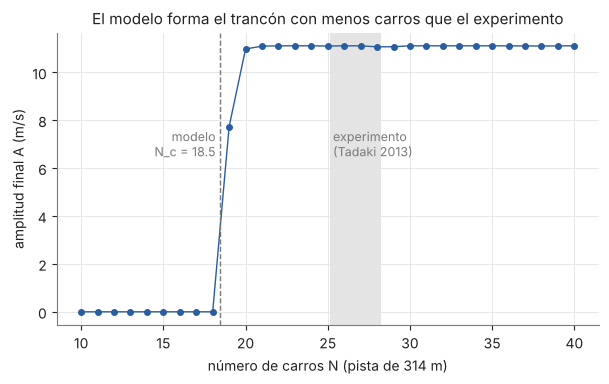

In [11]:
def patron_detenidos(x, v, L, dx=0.5, v_det=1.0):
    """Carros detenidos (v < v_det) por celda de dx metros, suavizado con ventana de 5 celdas."""
    n_celdas = int(round(L / dx))
    cuenta, _ = np.histogram(x[v < v_det] % L, bins=n_celdas, range=(0, L))
    ext = np.concatenate([cuenta[-2:], cuenta, cuenta[:2]])        # extremos circulares
    return np.convolve(ext, np.ones(5) / 5, mode="valid")


def velocidad_frente(t, X, V, L, t_ini=300.0, dt_lag=4.0, dx=0.5):
    """Velocidad (m/s) del patrón de carros detenidos: negativa = viaja hacia atrás."""
    paso_t = t[1] - t[0]
    k_lag = int(round(dt_lag / paso_t))
    lag_max = int(L / 6 / dx)
    medidas = []
    for k in range(int(t_ini / paso_t), len(t) - k_lag, 10):
        a = patron_detenidos(X[k], V[k], L, dx)
        b = patron_detenidos(X[k + k_lag], V[k + k_lag], L, dx)
        if a.sum() == 0 or b.sum() == 0:
            continue
        mejor, sup_mejor = 0, -1.0
        for lag in range(-lag_max, lag_max + 1):
            sup = np.sum(a * np.roll(b, -lag))                      # cuánto se parecen si se corre b
            if sup > sup_mejor:
                mejor, sup_mejor = lag, sup
        medidas.append(mejor * dx / dt_lag)
    return np.array(medidas)


def contar_trancones(v, v_det=1.0):
    """Número de grupos de carros detenidos: un grupo empieza donde hay un carro detenido sin otro detenido atrás."""
    det = v < v_det
    return int(np.sum(det & ~np.roll(det, 1)))


# 1. N crítico en 314 m (de 5.1) frente al experimento de Tadaki: rho_c entre 0.08 y 0.09 carros/m
print("1. N crítico, modelo: " + str(N_c_sim) + " (analítico " + str(round(N_c, 1)) + ") ; experimento: "
      + str(int(0.08 * L)) + " a " + str(int(0.09 * L)) + " (rho_c entre 0.08 y 0.09 carros/m)")
print("   El modelo da " + str(round(100 * (1 - N_c / (0.085 * L)))) + " % menos que el punto medio del experimento")

# 2. Densidad crítica en autopista: v_max = 120 km/h, mismo T, s0 y ell
rho_c_aut = 1.0 / (ell + s0 + (120 / 3.6) * T)
print("2. rho_c en autopista, modelo: " + str(round(rho_c_aut, 4)) + " carros/m ; publicado: ~0.025 carros/m")

# 3. Velocidad del trancón hacia atrás (corridas de 600 s, tau = 0.7 s)
print("3. Velocidad del trancón (publicado: ~20 km/h hacia atrás):")
for N_k in (25, 30, 34):
    t_k, X_k, V_k, s_min_k = simular(N_k, tau, tf=600.0)
    medidas = velocidad_frente(t_k, X_k, V_k, L)
    kmh = abs(medidas.mean()) * 3.6
    disp = medidas.std() * 3.6
    n_tr = [contar_trancones(V_k[k]) for k in range(int(300 / 0.5), len(t_k))]
    print("   N = " + str(N_k) + ": " + valor_inc(kmh, disp) + " km/h hacia atrás ; trancones simultáneos: "
          + str(min(n_tr)) + " a " + str(max(n_tr)))

# 4. N = 40 en 314 m
t_k, X_k, V_k, s_min_k = simular(40, tau, tf=1500.0)
print("4. N = 40, 314 m: amplitud final = " + str(round(amplitud_final(t_k, V_k), 2))
      + " m/s (el modelo predice trancón; el experimento de Tadaki es homogéneo)")

# 5. Sugiyama et al. 2008: pista de 230 m
N_c_230 = 230.0 / (ell + s0 + vmax * T)
print("5. Pista de 230 m: N crítico analítico = " + str(round(N_c_230, 1)))
for N_k in (13, 14, 22):
    t_k, X_k, V_k, s_min_k = simular(N_k, tau, L=230.0, tf=1500.0)
    print("   N = " + str(N_k) + ": amplitud final = " + str(round(amplitud_final(t_k, V_k), 2))
          + " m/s, distancia libre mínima = " + str(round(s_min_k, 2)) + " m")

# Figura: la comparación principal, amplitud vs N con el rango experimental
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.axvspan(0.08 * L, 0.09 * L, color="#d9d9d9", alpha=0.7, lw=0)
ax.text(0.08 * L + 0.2, 6.5, "experimento\n(Tadaki 2013)", fontsize=9, color=COLOR_REF)
ax.plot(Ns, A_fin_N, "o-", color=COLOR_DATO, ms=4, lw=1)
ax.axvline(N_c, color=COLOR_REF, ls="--", lw=1)
ax.text(N_c - 0.3, 6.5, "modelo\nN_c = " + str(round(N_c, 1)), fontsize=9, color=COLOR_REF, ha="right")
ax.set_xlabel("número de carros N (pista de 314 m)")
ax.set_ylabel("amplitud final A (m/s)")
ax.set_title("El modelo forma el trancón con menos carros que el experimento", fontsize=11, color=TINTA)
plt.show()

**Interpretación.**

| Comparación | Modelo | Publicado | Lectura |
|---|---|---|---|
| $N$ crítico en 314 m | 18–19 (analítico 18,5) | 25–28 (Tadaki 2013) | El modelo subestima ≈ 30 %: forma el trancón con menos carros |
| $\rho_c$ en autopista | 0,0255 carros/m | ≈ 0,025 carros/m | Coincide |
| Velocidad del trancón | ≈ 12 km/h hacia atrás | ≈ 20 km/h (Tadaki 2013, Sugiyama 2008) | El modelo es ≈ 40 % más lento |
| $N=40$ en 314 m | Predice trancón | Flujo homogéneo (Tadaki 2013) | No lo reproduce; Nakayama et al. 2016 reportan fallas del mismo modelo en $N=40$ |
| 22 carros en 230 m | Trancón (N crítico analítico 13,5) | Hay trancón (Sugiyama 2008) | Coincide |

- **Exactitud (criterio del curso, $|v_{exp}-v_{aceptado}|<2\sigma$).** La velocidad del trancón no cumple: $(12\pm1)$ km/h frente a ≈ 20 km/h (valor leído de los diagramas de los artículos, sin incertidumbre publicada) es una diferencia de ≈ 8 km/h, unas 8 veces la dispersión. La dispersión es chica (**precisión** buena: las mediciones de $N=25$, 30 y 34 son consistentes entre sí) pero el valor no es exacto. Tampoco coincide el $N$ crítico (≈ 30 % más bajo).
- **Lo que sí se reproduce:** el orden de magnitud del $N$ crítico, la densidad crítica de autopista, el sentido de la onda (hacia atrás) y el trancón en 230 m. El modelo explica *que* y *dónde* aparece el trancón, y de forma cuantitativa no ajusta bien *a qué velocidad viaja* ni *cuántos carros hacen falta*.
- **Un trancón vs varios.** En el modelo hay 2 o 3 trancones a la vez en $N=25$–34; los experimentos muestran uno. No verificamos la causa; se reporta como discrepancia.

## 6. Limitaciones
- **El modelo no reproduce las cantidades que se comparan con los experimentos.** El $N$ crítico es ≈ 30 % menor, el trancón viaja ≈ 40 % más lento y aparecen varios trancones donde el experimento tiene uno (5.3). Nakayama et al. (2016) ya reportan que este modelo falla en algunos casos (por ejemplo $N=40$); no verificamos la causa de las demás diferencias, así que no se la atribuimos a nada en particular.
- **$N=40$:** el modelo predice trancón y el experimento fue homogéneo (5.3).
- **$\tau$ es un parámetro ajustado.** Con el valor publicado (≈ 0,56 s) el crecimiento es muy lento (con 0,55 s la amplitud llega a 0,5 m/s en 1500 s). Usamos $\tau=0{,}7$ s y se reporta el barrido completo (4.3).
- **Choques con $\tau\ge0{,}8$ s:** la distancia libre mínima es negativa, así que esos casos no se usan para conclusiones.
- **Parámetros de otros experimentos:** $T$ y $s_0$ salen de Nakayama et al. (2016) y $\ell$, $L$, $v_{max}$ de Tadaki et al. (2013), no de una calibración con datos propios.
- **Paso de tiempo:** Euler es de primer orden. Se verificó con $\Delta t$ y $2\Delta t$ (5.2), pero no se estudió el error de forma sistemática; el efecto es de ≈ 0,1 m en las distancias extremas.
- **Criterio $\tau>T/2$:** se usa como criterio publicado, sin derivar el análisis de modos, y vale para longitudes de onda largas.
- **Simplificaciones:** un carril, conductores idénticos, reacción solo al carro de adelante, sin ruido.

## 7. Conexión con Ingeniería de Sistemas y Computación
- **Sistema multiagente:** cada carro sigue una regla local simple y el trancón es un comportamiento global que no está programado en ningún carro (animación de 4.1).
- **Paso de tiempo y costo de cómputo:** cada corrida de 1500 s son 75 000 pasos y toma ≈ 1 s; la comparación de 5.2 es la forma barata de comprobar que el paso elegido es suficiente.
- **Errores que no se ven:** usar `% L` en el anillo habría escondido los choques de la sección 4.3. Validar el programa contra un caso con respuesta conocida ($\delta=0$, 3.4) es lo que permite confiar en lo que viene después.
- **Validar un modelo contra datos ajenos:** la sección 5.3 es un ejemplo de cómo se contrasta una simulación con resultados publicados, y de reportar qué coincide y qué no.

## 8. Conclusiones
1. **Respuesta a la pregunta (en el modelo).** La reducción de velocidad de un solo carro se amplifica hasta un trancón cuando la densidad supera $\rho_c=1/(\ell+s_0+v_{max}T)\approx0{,}059$ carros/m ($N_c\approx18{,}5$ en 314 m), siempre que $\tau>T/2$. Por debajo de $\rho_c$ la perturbación se disipa. Las simulaciones lo confirman: estable hasta $N=18$ e inestable desde $N=19$, y el umbral de $\tau$ queda entre 0,5 y 0,55 s frente a $T/2=0{,}5$ s.
2. **Qué se validó.** La implementación contra la teoría (flujo uniforme, $N_c$, umbral de $\tau$) y el modelo contra los experimentos de Sugiyama (2008), Tadaki (2013) y Nakayama (2016): coincide el orden de magnitud, la densidad crítica de autopista, el sentido de la onda y el trancón en 230 m.
3. **Qué no coincide.** El $N$ crítico del modelo es ≈ 30 % menor que el medido, el trancón viaja a ≈ 12 km/h en vez de ≈ 20 km/h, aparecen varios trancones a la vez y $N=40$ no es homogéneo como en el experimento.
4. **Alcance.** Es un modelo de una regla local, útil para entender *por qué* aparece un trancón sin obstáculo y a partir de qué densidad, no para predecir con precisión el valor medido en una pista real.

## 9. Declaración de uso de IA generativa
Usamos Claude (Anthropic, modelo Claude Sonnet 5.5, en un proyecto de claude.ai) como asistente de análisis, código y redacción. Las decisiones del proyecto y la responsabilidad por el contenido son de los autores.

**Para qué se usó:**
- Leer los tres artículos de la sección 2.6 y extraer parámetros y resultados publicados (los artículos los aportamos nosotros).
- Analizar el archivo del experimento A de ARED (ajuste de $v$ contra $s$ y regresión de la aceleración), que llevó a descartar ARED como fuente de calibración.
- Escribir y ejecutar simulaciones exploratorias en Python (barrido de $\tau$, $N$ crítico, velocidad del trancón) y proponer la estructura y el código base de este notebook, incluidas las gráficas y la animación.
- Proponer la validación por literatura y redactar borradores de las celdas de texto y de la propuesta del proyecto.

**Cómo se verificó:**
- Las cifras publicadas se contrastaron con el texto completo de los artículos.
- El criterio $\tau>T/2$ se comprobó numéricamente (secciones 4.3 y 5.1).
- Este notebook se ejecuta de principio a fin sin errores y las cifras de las interpretaciones se contrastaron con sus salidas.
- Durante el proceso la verificación corrigió dos errores de la IA: el largo del carro y la velocidad de la onda del trancón.

**Responsabilidad.** Los autores respondemos por todo el contenido de este notebook y del póster, sin importar qué parte haya generado la IA.

**Por completar antes de entregar:**
- [ ] Quién escribió el código inicial de la simulación (`sim2.py`) y con qué ayuda de IA.
- [ ] Si se usó IA en el póster y para qué.
- [ ] Cualquier otra herramienta usada (otro asistente, corrector, traductor).

## 10. Referencias
- Bando, M., Hasebe, K., Nakayama, A., Shibata, A., Sugiyama, Y. (1995). *Dynamical model of traffic congestion and numerical simulation.* Physical Review E 51, 1035–1042.
- Nakayama, A. et al. (2016). *Quantitative explanation of circuit experiments and real traffic using the optimal velocity model.* New Journal of Physics 18, 043040. doi:10.1088/1367-2630/18/4/043040
- Sugiyama, Y. et al. (2008). *Traffic jams without bottlenecks: experimental evidence for the physical mechanism of the formation of a jam.* New Journal of Physics 10, 033001.
- Tadaki, S. et al. (2013). *Phase transition in traffic jam experiment on a circuit.* New Journal of Physics 15, 103034.
- Serway, R. A. y Jewett, J. W. *Physics for Scientists and Engineers with Modern Physics*, 10.ª ed. [indicar capítulos usados: cinemática y leyes de Newton].